# Pen Vis DSR

## import dataset

In [1]:
import pandas as pd

df = pd.read_csv('AB_final.csv')
df.head(3)

,pen,vis,dsr-org
0,79.0,285,0.71
1,82.5,285,0.71
2,80.9,290,0.74


In [2]:
# df.describe()

### Visualization

In [3]:
# import matplotlib.pyplot as plt
# import matplotlib as mpl
# import numpy as np

# # تنظیمات برای نمودار
# mpl.rcParams['font.family'] = 'Times New Roman'
# plt.style.use('seaborn-v0_8-whitegrid')

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# # plot (a): Penetration vs DSR(org)
# scatter1 = ax1.scatter(df['pen'], df['dsr-org'],
#                        s=50,                    
#                        c='steelblue',            
#                        edgecolor='w',           
#                        linewidth=0.5,           
#                        alpha=0.8,              
#                        zorder=3)                

# ax1.set_xlabel('Penetration (dmm)', fontsize=16, fontweight='bold', labelpad=10)
# ax1.set_ylabel('DSR (KPa)', fontsize=16, fontweight='bold', labelpad=10)
# ax1.set_title('Penetration vs DSR(org)', fontsize=18, fontweight='bold', pad=20)

# # تنظیمات تیک‌ها
# ax1.tick_params(axis='both', which='major', labelsize=14, width=1.5, length=5)
# ax1.grid(True, linestyle='--', alpha=0.6, zorder=1)

# # تنظیمات خطوط محور
# for spine in ax1.spines.values():
#     spine.set_linewidth(1.5)


# # plot (b): Viscosity vs DSR(org)
# scatter2 = ax2.scatter(df['vis'], df['dsr-org'],
#                        s=50,                    
#                        c= 'm',             
#                        edgecolor='w',           
#                        linewidth=0.5,           
#                        alpha=0.8,               
#                        zorder=3)                

# ax2.set_xlabel('Viscosity (Pa.s)', fontsize=16, fontweight='bold', labelpad=10)
# ax2.set_ylabel('DSR (KPa)', fontsize=16, fontweight='bold', labelpad=10)
# ax2.set_title('Viscosity vs DSR(org)', fontsize=18, fontweight='bold', pad=20)

# # تنظیمات تیک‌ها 
# ax2.tick_params(axis='both', which='major', labelsize=14, width=1.5, length=5)
# ax2.grid(True, linestyle='--', alpha=0.6, zorder=1)

# # تنظیمات خطوط محور 
# for spine in ax2.spines.values():
#     spine.set_linewidth(1.5)


# plt.tight_layout(pad=2.0)

# # plt.savefig('figure_paper.pdf', format='pdf', dpi=300, bbox_inches='tight')
# # plt.savefig('figure_paper.png', format='png', dpi=300, bbox_inches='tight')

# plt.show()

## define x , y

In [2]:
import numpy as np

x = df[['pen', 'vis']].values   # 2D
y = df['dsr-org'].values        # 1D

x_pendsr = df[['pen']].values
y_pendsr = df['dsr-org'].values

x_visdsr = df[['vis']].values
y_visdsr = df['dsr-org'].values

## spliting

In [5]:
# # finding best random state 

# from sklearn.model_selection import train_test_split
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import r2_score

# import time
# t1 = time.time()
# lst = []
# for i in range(1,1000):
#     x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=i) 
#     rfr = RandomForestRegressor() 
#     rfr.fit(x_train, y_train)
#     yhat_test = rfr.predict(x_test)
#     r2 = r2_score(y_test, yhat_test)
#     lst.append(r2)
# t2 = time.time()

# print(f"run time: {round((t2 - t1) / 60 , 0)} min")
# print(f"R2_score = {round(max(lst),2)}")
# print(f"random_state = {np.argmax(lst) + 1}")

In [3]:
from sklearn.model_selection import train_test_split

# x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=392)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=874)

x_train_pendsr, x_test_pendsr, y_train_pendsr, y_test_pendsr = train_test_split(x_pendsr, y_pendsr, test_size=0.25, random_state=874)
x_train_visdsr, x_test_visdsr, y_train_visdsr, y_test_visdsr = train_test_split(x_visdsr, y_visdsr, test_size=0.25, random_state=874)

## fit the model

In [4]:
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor(n_estimators=100, random_state=1)
rfr.fit(x_train, y_train)

rfr_pendsr = RandomForestRegressor(n_estimators=100, random_state=1)
rfr_pendsr.fit(x_train_pendsr, y_train_pendsr)

rfr_visdsr = RandomForestRegressor(n_estimators=100, random_state=1)
rfr_visdsr.fit(x_train_visdsr, y_train_visdsr)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## predict test data

In [5]:
yhat_test = rfr.predict(x_test)

yhat_test_pendsr = rfr_pendsr.predict(x_test_pendsr)
yhat_test_visdsr = rfr_visdsr.predict(x_test_visdsr)

## evaluating the moodel

In [6]:
from sklearn.metrics import r2_score

print("r2-score (train data): %0.2f" % r2_score(y_train, rfr.predict(x_train)))
print("r2-score (test data): %0.2f" % r2_score(y_test, yhat_test))
print("----------------------")
print("r2-score (train_pendsr data): %0.2f" % r2_score(y_train_pendsr, rfr_pendsr.predict(x_train_pendsr)))
print("r2-score (test_pendsr data): %0.2f" % r2_score(y_test_pendsr, yhat_test_pendsr))
print("r2-score (train_visdsr data): %0.2f" % r2_score(y_train_visdsr, rfr_visdsr.predict(x_train_visdsr)))
print("r2-score (test_visdsr data): %0.2f" % r2_score(y_test_visdsr, yhat_test_visdsr))

r2-score (train data): 0.98
r2-score (test data): 0.97
----------------------
r2-score (train_pendsr data): 0.85
r2-score (test_pendsr data): 0.83
r2-score (train_visdsr data): 0.93
r2-score (test_visdsr data): 0.93


In [7]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

print(f"MSE (train data): {mean_squared_error(y_train, rfr.predict(x_train))}")
print(f"RMSE (train data): {np.sqrt(mean_squared_error(y_train, rfr.predict(x_train)))}")
print(f"MAE (train data): {mean_absolute_error(y_train, rfr.predict(x_train))}")

print(f"MSE (test data): {mean_squared_error(y_test, yhat_test)}")
print(f"RMSE (test data): {np.sqrt(mean_squared_error(y_test, yhat_test))}")
print(f"MAE (test data): {mean_absolute_error(y_test, yhat_test)}")

print('------------')

print(f"MSE (train_pendsr data): {mean_squared_error(y_train_pendsr, rfr_pendsr.predict(x_train_pendsr))}")
print(f"RMSE (train_pendsr data): {np.sqrt(mean_squared_error(y_train_pendsr, rfr_pendsr.predict(x_train_pendsr)))}")
print(f"MAE (train_pendsr data): {mean_absolute_error(y_train_pendsr, rfr_pendsr.predict(x_train_pendsr))}")

print(f"MSE (test_pendsr data): {mean_squared_error(y_test_pendsr, yhat_test_pendsr)}")
print(f"RMSE (test_pendsr data): {np.sqrt(mean_squared_error(y_test_pendsr, yhat_test_pendsr))}")
print(f"MAE (test_pendsr data): {mean_absolute_error(y_test_pendsr, yhat_test_pendsr)}")

print('------------')

print(f"MSE (train_visdsr data): {mean_squared_error(y_train_visdsr, rfr_visdsr.predict(x_train_visdsr))}")
print(f"RMSE (train_visdsr data): {np.sqrt(mean_squared_error(y_train_visdsr, rfr_visdsr.predict(x_train_visdsr)))}")
print(f"MAE (train_visdsr data): {mean_absolute_error(y_train_visdsr, rfr_visdsr.predict(x_train_visdsr))}")

print(f"MSE (test_visdsr data): {mean_squared_error(y_test_visdsr, yhat_test_visdsr)}")
print(f"RMSE (test_visdsr data): {np.sqrt(mean_squared_error(y_test_visdsr, yhat_test_visdsr))}")
print(f"MAE (test_visdsr data): {mean_absolute_error(y_test_visdsr, yhat_test_visdsr)}")

MSE (train data): 0.0002922262885627907
RMSE (train data): 0.017094627476572595
MAE (train data): 0.00873372609186463
MSE (test data): 0.0005316720508442677
RMSE (test data): 0.023058014893833936
MAE (test data): 0.011050425530346575
------------
MSE (train_pendsr data): 0.0023200197075755684
RMSE (train_pendsr data): 0.04816658289286846
MAE (train_pendsr data): 0.03656385205236217
MSE (test_pendsr data): 0.002652844709736772
RMSE (test_pendsr data): 0.051505773557308815
MAE (test_pendsr data): 0.03906395842722046
------------
MSE (train_visdsr data): 0.0011240319008925452
RMSE (train_visdsr data): 0.03352658498703
MAE (train_visdsr data): 0.021560936203199085
MSE (test_visdsr data): 0.0011096254911351783
RMSE (test_visdsr data): 0.03331104157986025
MAE (test_visdsr data): 0.021222550190216037


## predict new data

In [8]:
print(rfr.predict([[79, 285]]))

print(rfr_pendsr.predict([[79]]))
print(rfr_visdsr.predict([[285]]))

[0.73215]
[0.77934095]
[0.72565]


## feature importance

In [9]:
importances = rfr.feature_importances_
X = df[['pen', 'vis']]
feature_names = X.columns

print(importances)
print(feature_names)

[0.11324362 0.88675638]
Index(['pen', 'vis'], dtype='object')


In [10]:
fi = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
fi = fi.sort_values(by='Importance', ascending=False)
print(fi)

  Feature  Importance
1     vis    0.886756
0     pen    0.113244


## save the model

In [14]:
# import joblib

# joblib.dump(rfr, 'rfr_model.pkl')

## load the model

In [15]:
# import joblib

# rfr = joblib.load('rfr_model.pkl')

pen dsr

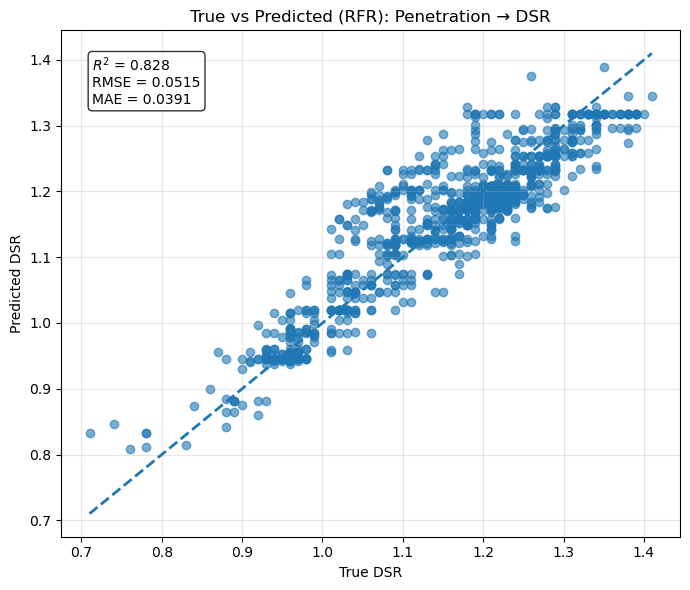

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Prediction
y_pred_pen = rfr_pendsr.predict(x_test_pendsr)

# Metrics
r2_pen = r2_score(y_test_pendsr, y_pred_pen)
rmse_pen = np.sqrt(mean_squared_error(y_test_pendsr, y_pred_pen))
mae_pen = mean_absolute_error(y_test_pendsr, y_pred_pen)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(y_test_pendsr, y_pred_pen, alpha=0.6)

min_val = min(y_test_pendsr.min(), y_pred_pen.min())
max_val = max(y_test_pendsr.max(), y_pred_pen.max())

plt.plot([min_val, max_val], [min_val, max_val], '--', linewidth=2)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (RFR): Penetration → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_pen:.3f}\nRMSE = {rmse_pen:.4f}\nMAE = {mae_pen:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_pen-dsr-RF.png', dpi=600)
plt.show()

vis dsr

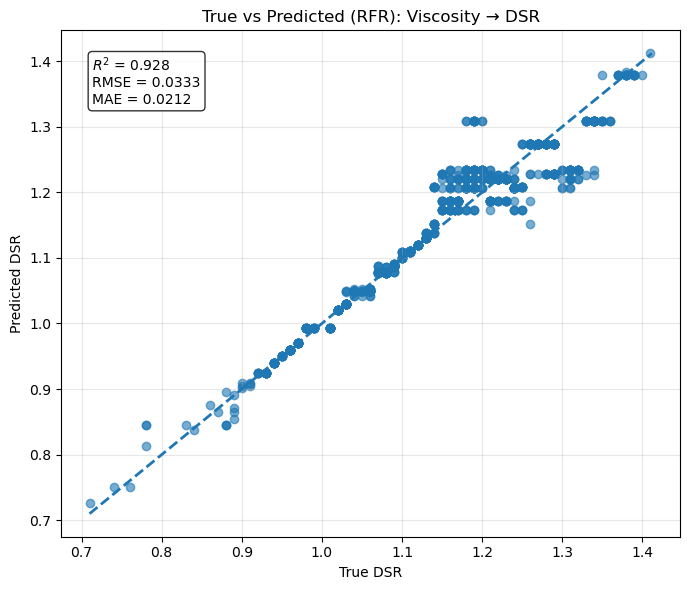

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Prediction
y_pred_vis = rfr_visdsr.predict(x_test_visdsr)

# Metrics
r2_vis = r2_score(y_test_visdsr, y_pred_vis)
rmse_vis = np.sqrt(mean_squared_error(y_test_visdsr, y_pred_vis))
mae_vis = mean_absolute_error(y_test_visdsr, y_pred_vis)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(y_test_visdsr, y_pred_vis, alpha=0.6)

min_val = min(y_test_visdsr.min(), y_pred_vis.min())
max_val = max(y_test_visdsr.max(), y_pred_vis.max())

plt.plot([min_val, max_val], [min_val, max_val], '--', linewidth=2)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (RFR): Viscosity → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_vis:.3f}\nRMSE = {rmse_vis:.4f}\nMAE = {mae_vis:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_vis-dsr-RF.png', dpi=600)
plt.show()

pen, vis dsr

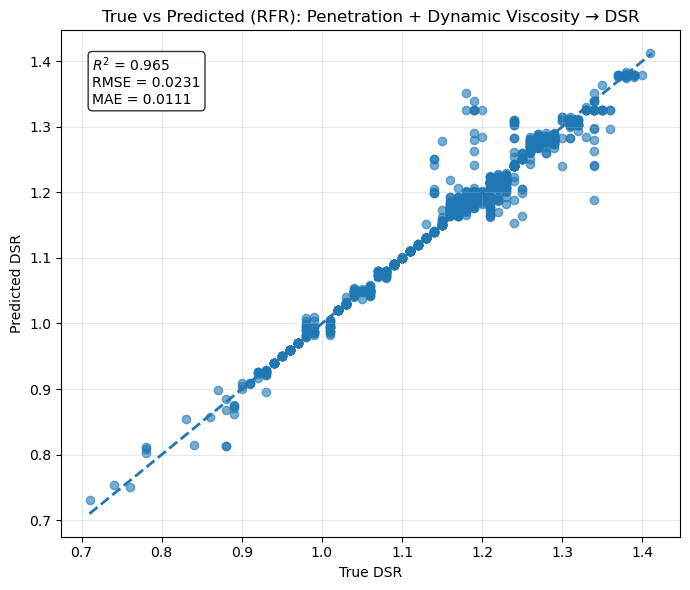

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Prediction
y_pred_pen_vis = rfr.predict(x_test)

# Metrics
r2_pen_vis = r2_score(y_test, y_pred_pen_vis)
rmse_pen_vis = np.sqrt(mean_squared_error(y_test, y_pred_pen_vis))
mae_pen_vis = mean_absolute_error(y_test, y_pred_pen_vis)

# Plot
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_pen_vis, alpha=0.6)

min_val = min(y_test.min(), y_pred_pen_vis.min())
max_val = max(y_test.max(), y_pred_pen_vis.max())

plt.plot([min_val, max_val], [min_val, max_val], '--', linewidth=2)

plt.xlabel('True DSR')
plt.ylabel('Predicted DSR')
plt.title('True vs Predicted (RFR): Penetration + Dynamic Viscosity → DSR')

plt.text(
    0.05, 0.95,
    f'$R^2$ = {r2_pen_vis:.3f}\nRMSE = {rmse_pen_vis:.4f}\nMAE = {mae_pen_vis:.4f}',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('true_vs_pred_penvis-dsr-RF.png', dpi=600)

plt.show()

